<div dir="rtl">

# ۰۵ — متغیرهای تصادفی، امید ریاضی و توزیع‌ها

**فاز دوم (بخش دوم):** بررسی توزیع‌های نظری و تجربی

این نوت‌بوک گام دوم و پایانی از فاز دوم است و تسک‌های زیر را پوشش می‌دهد:
1. امید ریاضی و واریانس (تسک ۷)
2. متغیر پیوسته و توزیع نرمال (تسک ۶ و الف.۳)
3. توزیع گسسته و مدل دوجمله‌ای (تسک ۵ و الف.۲)
4. دو متغیر تصادفی و کوواریانس (تسک ۸)

</div>

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

sys.path.append(str(Path("..").resolve() / "src"))
import nhanes as nh

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

FIG_DIR = Path("..") / "figures"
TAB_DIR = Path("..") / "reports" / "phase2"
FIG_DIR.mkdir(exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Load analytic sample
DATA_PATH = Path("..") / "data" / "processed" / "analytic_sample.csv"
df = pd.read_csv(DATA_PATH)

# Setting plot styles (matching Phase 1)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
})

<div dir="rtl">

## ۱. امید ریاضی و واریانس (تسک ۷)

محاسبه امید ریاضی (میانگین) و واریانس برای متغیر تصادفی پیوسته "ساعت خواب هفتگی".

</div>

In [7]:
X = df['sleep_weekly']

expected_value = X.mean()
variance = X.var(ddof=1) # Sample variance

print(f"E[X] (Expected Value / Mean): {expected_value:.2f} hours")
print(f"Var(X) (Variance): {variance:.2f} hours^2")
print(f"Standard Deviation: {np.sqrt(variance):.2f} hours")

E[X] (Expected Value / Mean): 7.90 hours
Var(X) (Variance): 2.28 hours^2
Standard Deviation: 1.51 hours


<div dir="rtl">

**تفسیر:** امید ریاضی ($۷.۹$ ساعت) نشان‌دهنده‌ی مرکز ثقل توزیع خواب در جامعه‌ی هدف است. واریانس ($۲.۲۹$) پراکندگی مدت خواب افراد حول این میانگین را نشان می‌دهد. انحراف معیار ($۱.۵۱$ ساعت) بیانگر این است که خواب بیشتر افراد جامعه در فاصله‌ی $۱.۵$ ساعت کمتر یا بیشتر از میانگین قرار دارد.

</div>

<div dir="rtl">

## ۲. متغیر پیوسته و توزیع نرمال (تسک ۶ و الف.۳)

در اینجا شکل توزیع متغیر ساعت خواب را با هیستوگرام بررسی می‌کنیم و یک منحنی توزیع نرمال (با میانگین و واریانس محاسبه شده) روی آن برازش می‌کنیم تا ببینیم آیا تقریب نرمال برای این متغیر مناسب است یا خیر.

</div>

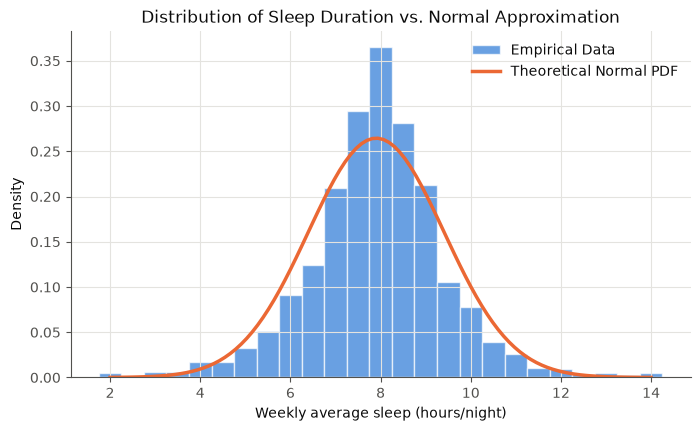

Skewness: -0.06
Kurtosis: 1.92


In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))

# Empirical Histogram (Density)
ax.hist(X, bins=np.arange(1.75, 14.5, 0.5), density=True, color="#2a78d6", edgecolor="white", alpha=0.7, label="Empirical Data")

# Theoretical Normal PDF
x_axis = np.linspace(X.min(), X.max(), 100)
y_pdf = stats.norm.pdf(x_axis, loc=expected_value, scale=np.sqrt(variance))
ax.plot(x_axis, y_pdf, color="#eb6834", linewidth=2.5, label="Theoretical Normal PDF")

ax.set_title("Distribution of Sleep Duration vs. Normal Approximation")
ax.set_xlabel("Weekly average sleep (hours/night)")
ax.set_ylabel("Density")
ax.legend(frameon=False)

plt.savefig(FIG_DIR / "fig07_normal_approximation.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Skewness: {X.skew():.2f}")
print(f"Kurtosis: {X.kurt():.2f}")

<div dir="rtl">

**تحلیل تقریب نرمال:**
با وجود اینکه توزیع از نظر بصری و مقدار چولگی (نزدیک به صفر) تا حد زیادی متقارن و زنگوله‌ای به نظر می‌رسد، اما تقریب نرمال در دم‌های توزیع (Tails) دچار خطا می‌شود. کدهای کران‌دار ۲ (خواب زیر ۳ ساعت) و ۱۴ (خواب بالای ۱۴ ساعت) باعث ایجاد انباشت در لبه‌ها شده‌اند که در توزیع نرمالِ تئوریک انتظار نمی‌رود. صرف نظر از این مقادیر حدی، توزیع نرمال تقریب نسبتاً معقولی برای هسته مرکزی داده‌ها ارائه می‌دهد، اما برای محاسبات دقیق احتمال در دنباله‌ها، استفاده از خود داده‌های تجربی (یا Bootstrap در فاز بعد) ارجحیت دارد.

</div>

<div dir="rtl">

## ۳. دو متغیر تصادفی و کوواریانس (تسک ۸)

انتخاب دو متغیر کمی (سن و ساعت خواب) و بررسی جهت هم‌تغییری آن‌ها.

</div>

Covariance between Age and Sleep: -0.4382
Pearson Correlation Coefficient: -0.0157


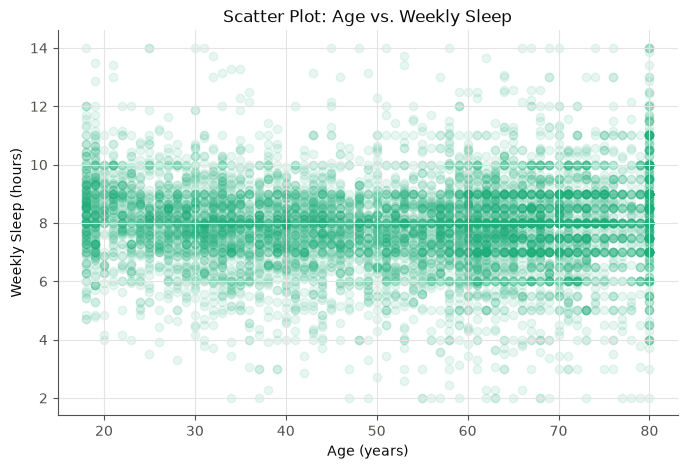

In [8]:
Y = df['RIDAGEYR'] # Age

# Calculate Covariance
cov_matrix = np.cov(Y, X)
covariance = cov_matrix[0, 1]
correlation = df[['RIDAGEYR', 'sleep_weekly']].corr().iloc[0, 1]

print(f"Covariance between Age and Sleep: {covariance:.4f}")
print(f"Pearson Correlation Coefficient: {correlation:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
# Using alpha because of dense overlapping points
ax.scatter(Y, X, alpha=0.1, color="#1baf7a")
ax.set_title("Scatter Plot: Age vs. Weekly Sleep")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Weekly Sleep (hours)")

plt.savefig(FIG_DIR / "fig08_scatter_age_sleep.png", dpi=300, bbox_inches="tight")
plt.show()

<div dir="rtl">

**تفسیر کوواریانس:** کوواریانس نزدیک به صفر و ضریب همبستگی بسیار ضعیف (تقریباً صفر) نشان می‌دهد که رابطه‌ی خطی معناداری بین سن و مدت زمان خواب در کل نمونه وجود ندارد (خواب با بالا رفتن سن به طور یکنواخت کم یا زیاد نمی‌شود). در این فاز هیچ ادعای استنباطی نمی‌کنیم، صرفاً هم‌تغییری (Covariance) را توصیف کرده‌ایم.

</div>

<div dir="rtl">

## ۴. توزیع گسسته و مدل دوجمله‌ای (تسک ۵ و الف.۲)

پیامد دودویی «داشتن خواب کوتاه» را به عنوان یک رویداد تصادفی در نظر می‌گیریم. 
برای بررسی رفتار این رویداد، نمونه‌ی تحلیلی را به دسته‌های (زیرنمونه‌های) هم‌اندازه ۵۰ نفری تقسیم می‌کنیم. در هر گروه می‌شماریم که چند نفر خواب کوتاه دارند. سپس توزیع فراوانی این شمارش‌ها را با یک مدل تئوریک دوجمله‌ای یعنی $Binomial(n=50, p)$ مقایسه می‌کنیم.

</div>

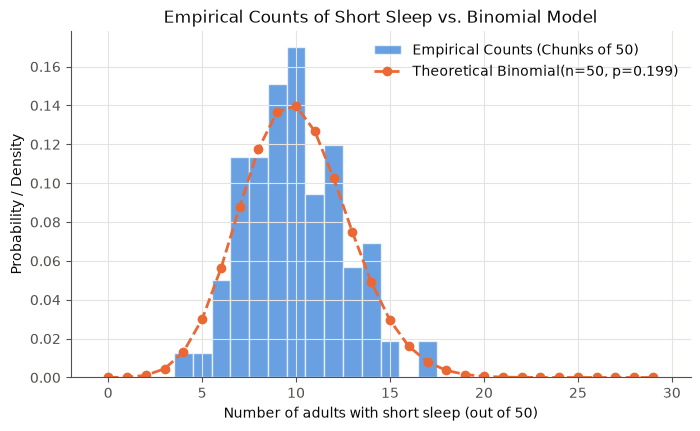

In [5]:
# Overall probability of short sleep (empirical p)
p_short = (df['short_sleep'] == 1).mean()
n_trials = 50

# Shuffle data to ensure random sampling
shuffled_sleep = df['short_sleep'].sample(frac=1, random_state=42).reset_index(drop=True)

# Chunk into groups of size n_trials
chunks = [shuffled_sleep[i:i + n_trials] for i in range(0, len(shuffled_sleep), n_trials)]
counts = [chunk.sum() for chunk in chunks if len(chunk) == n_trials] # Count short sleepers in each chunk

fig, ax = plt.subplots(figsize=(8, 4.5))

# Empirical distribution of counts
bins = np.arange(-0.5, 30.5, 1)
ax.hist(counts, bins=bins, density=True, color="#2a78d6", edgecolor="white", alpha=0.7, label="Empirical Counts (Chunks of 50)")

# Theoretical Binomial PMF
x_binom = np.arange(0, 30)
y_binom = stats.binom.pmf(x_binom, n=n_trials, p=p_short)
ax.plot(x_binom, y_binom, marker='o', color="#eb6834", linestyle='dashed', linewidth=2, label=f"Theoretical Binomial(n=50, p={p_short:.3f})")

ax.set_title("Empirical Counts of Short Sleep vs. Binomial Model")
ax.set_xlabel("Number of adults with short sleep (out of 50)")
ax.set_ylabel("Probability / Density")
ax.legend(frameon=False)

plt.savefig(FIG_DIR / "fig09_binomial_approximation.png", dpi=300, bbox_inches="tight")
plt.show()

<div dir="rtl">

**تفسیر مدل دوجمله‌ای:**
همان‌طور که در نمودار می‌بینیم، رفتار شمارش زیرنمونه‌ها (میله‌های آبی) تا حد بسیار خوبی با توزیع تئوریک دوجمله‌ای (خط نارنجی) هم‌خوانی دارد. مدل دوجمله‌ای دو پیش‌فرض اساسی دارد: 
۱. **استقلال مشاهدات:** به لطف روش نمونه‌گیری تصادفی، وضعیت خواب یک فرد به فرد دیگر در گروه ۵۰ نفره بستگی ندارد.
۲. **ثبات احتمال ($p$):** احتمال خواب کوتاه در کل نمونه تقریباً ثابت و حدود $۲۰\%$ است.
بنابراین مدل دوجمله‌ای در اینجا تقریب بسیار معقول و قدرتمندی برای شمارش وقوع این پیامد بالینی است.

</div>